# Notebook 3 — Feature Derivation, Labelling and Train/Test Split

**Goal:** turn raw sensor readings into a clean table the models can learn from.

Steps:
1. Build the **RUL** column and the yes/no **label** (fails within 30 cycles?)
2. **Drop** useless columns (found in EDA)
3. **Derive new features**: rolling mean and rolling standard deviation of each sensor
4. Prepare the **test set** the same way
5. Explain the **engine-wise split** and **scaling**
6. Save the processed data for Notebooks 4 and 5

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

DATA_DIR = "../data/raw/CMAPSSData"   # on Colab: folder where you uploaded the 3 files

index_cols   = ["unit", "cycle"]
setting_cols = ["setting_1", "setting_2", "setting_3"]
sensor_cols  = [f"s{i}" for i in range(1, 22)]
col_names    = index_cols + setting_cols + sensor_cols

train = pd.read_csv(f"{DATA_DIR}/train_FD001.txt", sep=r"\s+", header=None, names=col_names)
test  = pd.read_csv(f"{DATA_DIR}/test_FD001.txt",  sep=r"\s+", header=None, names=col_names)
rul   = pd.read_csv(f"{DATA_DIR}/RUL_FD001.txt",   sep=r"\s+", header=None, names=["true_RUL"])
print("train:", train.shape, "| test:", test.shape)

train: (20631, 26) | test: (13096, 26)


## 1. RUL and label

**Training set** — every engine runs to failure, so for each row:

$$\text{RUL} = \text{last cycle of the engine} - \text{current cycle}$$

**Test set** — data stops early; `RUL_FD001.txt` gives the RUL at the *last* row of each engine, so for each row:

$$\text{RUL} = (\text{last cycle seen} + \text{true RUL at last cycle}) - \text{current cycle}$$

**Label:** `1` if RUL ≤ 30 (fails within 30 cycles → schedule maintenance), else `0`.

**Why 30 cycles?** It is a realistic warning window — enough time to plan a repair, order parts and schedule the aircraft. It is also the window used in Microsoft's Azure predictive-maintenance template on this same data.

In [2]:
WINDOW = 30   # "fails soon" = within 30 cycles

# Train RUL
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]

# Test RUL
last_seen = test.groupby("unit")["cycle"].max()
total_life = last_seen + rul["true_RUL"].values          # row i of RUL file = engine i
test["RUL"] = test["unit"].map(total_life) - test["cycle"]

train["label"] = (train["RUL"] <= WINDOW).astype(int)
test["label"]  = (test["RUL"]  <= WINDOW).astype(int)

print(f"Train positive share: {train['label'].mean():.1%}   | Test positive share: {test['label'].mean():.1%}")

Train positive share: 15.0%   | Test positive share: 2.5%


**Important observation:** the test set has far fewer positive rows (≈2.5%) than the training set (15%).
**Why?** Test engines are stopped *before* failure, so most of their rows are from the healthy part of life; only 25 of the 100 test engines reach their last 30 cycles.

**Consequence:** on the test set, even a good model will have **lower precision** (positives are rare, so a few false alarms weigh a lot). We will therefore also evaluate in a second, realistic way in Notebook 5:
**one prediction per engine at its last available cycle** — "should this engine go for maintenance now?" (25 yes / 75 no).

## 2. Drop useless columns

Same rule as in the EDA: drop any setting/sensor whose standard deviation in the **training** set is below 0.01.
(The rule is decided on the training set only — the test set is never used to make decisions.)

In [3]:
std = train[setting_cols + sensor_cols].std()
drop_cols = std.index[std < 0.01].tolist()
useful_sensors = [s for s in sensor_cols if s not in drop_cols]
print("Dropped:", drop_cols)
print("Kept sensors:", useful_sensors)

Dropped: ['setting_1', 'setting_2', 'setting_3', 's1', 's5', 's6', 's10', 's16', 's18', 's19']
Kept sensors: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 3. Derived features: rolling mean and rolling standard deviation

**Problem seen in EDA:** individual readings are **noisy**, but the **trend** over recent cycles clearly shows wear.

**Solution:** for each engine and each useful sensor, compute over the **last 5 cycles** (current one included):
- **Rolling mean** → smooths out noise; shows the sensor's *recent level*.
- **Rolling standard deviation** → shows how *unstable* the sensor has recently been.

**Why only past cycles?** At prediction time we only know the past. Using future cycles would be **data leakage** — the model would "cheat".
The rolling window is computed **per engine** so one engine's data never mixes into another's.

**Why window = 5?** Small enough to react quickly to wear, large enough to smooth noise. It is a design choice we can justify and change.
At the start of an engine's life (cycles 1–4) fewer than 5 cycles exist, so we use whatever is available (`min_periods=1`); the std of a single value is set to 0.

In [4]:
ROLL = 5

def add_rolling_features(df, sensors, window=ROLL):
    df = df.sort_values(["unit", "cycle"]).copy()
    g = df.groupby("unit")[sensors]
    means = g.rolling(window, min_periods=1).mean().reset_index(level=0, drop=True).loc[df.index]
    stds  = g.rolling(window, min_periods=1).std().reset_index(level=0, drop=True).loc[df.index].fillna(0)
    df[[f"{s}_mean{window}" for s in sensors]] = means[sensors].values
    df[[f"{s}_std{window}"  for s in sensors]] = stds[sensors].values
    return df

train_fe = add_rolling_features(train, useful_sensors)
test_fe  = add_rolling_features(test,  useful_sensors)

feature_cols = (useful_sensors
                + [f"{s}_mean{ROLL}" for s in useful_sensors]
                + [f"{s}_std{ROLL}"  for s in useful_sensors])
print("Number of features:", len(feature_cols))
train_fe[["unit", "cycle", "s11", f"s11_mean{ROLL}", f"s11_std{ROLL}", "RUL", "label"]].head(8)

Number of features: 42


,unit,cycle,s11,s11_mean5,s11_std5,RUL,label
0,1,1,47.47,47.470,0.000000,191,0
1,1,2,47.49,47.480,0.014142,190,0
2,1,3,47.27,47.410,0.121655,189,0
3,1,4,47.13,47.340,0.171659,188,0
4,1,5,47.28,47.328,0.151063,187,0
5,1,6,47.16,47.266,0.141527,186,0
6,1,7,47.36,47.240,0.094074,185,0
7,1,8,47.24,47.234,0.092628,184,0


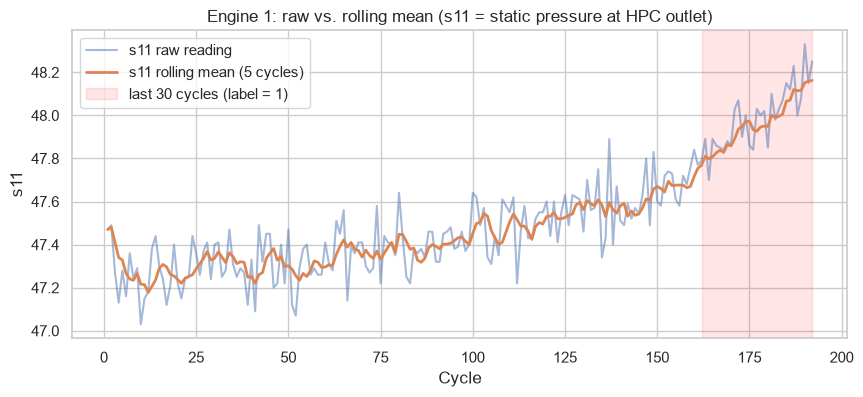

In [5]:
# Visual check: raw sensor vs. its rolling mean for one engine
d = train_fe[train_fe["unit"] == 1]
plt.figure(figsize=(10, 4))
plt.plot(d["cycle"], d["s11"], alpha=0.5, label="s11 raw reading")
plt.plot(d["cycle"], d[f"s11_mean{ROLL}"], linewidth=2, label=f"s11 rolling mean ({ROLL} cycles)")
plt.axvspan(d["cycle"].max() - WINDOW, d["cycle"].max(), color="red", alpha=0.1, label="last 30 cycles (label = 1)")
plt.title("Engine 1: raw vs. rolling mean (s11 = static pressure at HPC outlet)")
plt.xlabel("Cycle"); plt.ylabel("s11"); plt.legend(); plt.show()

**Takeaway:** the rolling mean removes most of the cycle-to-cycle noise and makes the upward wear trend in the red zone much easier to see.

In [6]:
# Does the derived feature separate the classes better than the raw reading?
from sklearn.metrics import roc_auc_score
check = pd.DataFrame({
    "raw sensor": [roc_auc_score(train_fe["label"], train_fe[s]) for s in useful_sensors],
    "rolling mean": [roc_auc_score(train_fe["label"], train_fe[f"{s}_mean{ROLL}"]) for s in useful_sensors],
}, index=useful_sensors)
# AUC below 0.5 just means the sensor goes DOWN with wear; flip so 0.5 = useless, 1.0 = perfect
check = check.where(check >= 0.5, 1 - check).round(3)
check["improvement"] = (check["rolling mean"] - check["raw sensor"]).round(3)
check.sort_values("rolling mean", ascending=False)

,raw sensor,rolling mean,improvement
s11,0.968,0.981,0.013
s4,0.961,0.980,0.019
s15,0.947,0.979,0.032
s21,0.941,0.977,0.036
s17,0.922,0.975,0.053
s20,0.938,0.975,0.037
s2,0.929,0.974,0.045
s12,0.956,0.973,0.017
s3,0.916,0.973,0.057
s7,0.951,0.972,0.021


**How to read this:** ROC-AUC of a *single column* = probability that a randomly chosen "fails soon" row has a more extreme value than a randomly chosen healthy row.
0.5 = useless, 1.0 = perfect separation. The rolling mean scores **higher** than the raw reading for 12 of the 14 sensors (up to +0.06) → the derived features are **justified by evidence**, not just added blindly.
The two exceptions, s9 and s14, are the weak, engine-dependent sensors seen in the EDA — smoothing cannot add information that isn't there.

## 4. Train/test split — **by engine**

We do **not** shuffle rows randomly into train and test. Rows from the same engine are strongly related (cycle 100 looks almost the same as cycle 101).
If engine 7's cycle 100 were in training and cycle 101 in testing, the model would just "remember" engine 7 → **falsely high scores** (data leakage).

How we avoid it:
- **Final test:** NASA's separate test set = **100 different engines** never seen in training. ✔
- **Cross-validation / tuning (Notebooks 4–5):** `GroupKFold` with `groups = unit`, so each fold holds out **whole engines**. ✔

## 5. Scaling

Sensors have very different units and ranges (e.g. temperature ≈ 1,590 °R vs. bypass ratio ≈ 8.4).
Logistic regression and regularization are sensitive to scale (a large-valued feature would be penalised differently), so we apply **StandardScaler** (mean 0, std 1).

The scaler is placed **inside a scikit-learn `Pipeline`** in Notebook 4, so it is fitted on the training folds only — never on validation or test data (another leakage guard). Tree models don't need scaling, but it does no harm.

In [7]:
import os, json
os.makedirs("../data/processed", exist_ok=True)

keep = ["unit", "cycle"] + feature_cols + ["RUL", "label"]
train_fe[keep].to_csv("../data/processed/train_features.csv", index=False)
test_fe[keep].to_csv("../data/processed/test_features.csv", index=False)
with open("../data/processed/feature_cols.json", "w") as f:
    json.dump(feature_cols, f, indent=1)

print("Saved:", train_fe[keep].shape, test_fe[keep].shape)

Saved: (20631, 46) (13096, 46)


## Summary

| Step | What we did | Why |
|---|---|---|
| Label | RUL ≤ 30 → 1, else 0 | Maintenance is a yes/no decision within a planning window |
| Drop columns | Settings + flat sensors removed | They carry no information about wear |
| Rolling mean (5) | Smoothed recent level of each sensor | Removes noise, shows the wear trend |
| Rolling std (5) | Recent instability of each sensor | Unstable readings can signal degradation |
| Split by engine | NASA's separate test engines + GroupKFold | Prevents leakage between related rows |
| Scaling | StandardScaler inside a Pipeline | Fair comparison of features; required for regularization |

## Likely viva questions
- *What is RUL and how did you compute it?* → Cycles left before failure: last cycle − current cycle (train); last seen + given RUL − current cycle (test).
- *Why rolling features?* → Single readings are noisy; the trend over recent cycles reflects wear. We showed the rolling mean separates the classes better (higher AUC).
- *Isn't a rolling window cheating?* → No — it uses only the current and previous cycles, which are known at prediction time.
- *Why not split rows randomly?* → Consecutive rows of one engine are nearly identical; random splitting leaks information and inflates scores.
- *Why scale inside a Pipeline?* → So the scaler only learns from training data in each fold.

**Next → Notebook 4: Classification, regularization and hyperparameter tuning.**